### Processes and Multiprocessing

**Multiprocessing** in Python is the primary mechanism for achieving true parallelism on multi-core systems, especially for CPU-bound tasks. It sidesteps the Global Interpreter Lock (GIL) by spawning separate OS processes, each with its own Python interpreter and memory space.

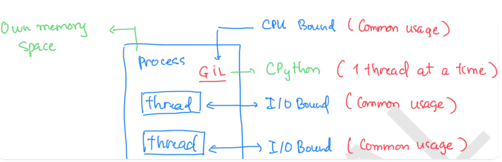

Why it exists:
- Each process runs an independent Python interpreter -> no GIL sharing
- Processes **do not** share memory directly (unlike threads) -> communication happens via explicit mechanisms (queue, pipe, etc.)
- High isolation -> Good for fault tolerance and security

**Comparing**:
<table>
    <tr>
        <td>Feature</td>
        <td>Thread</td>
        <td>Process</td>
    </tr>
    <tr>
        <td>Memory</td>
        <td>Shared</td>
        <td>Separate</td>
    </tr>
    <tr>
        <td>Creation overhead</td>
        <td>Low</td>
        <td>High</td>
    </tr>
    <tr>
        <td>Parallelism</td>
        <td>Limited</td>
        <td>True</td>
    </tr>
    <tr>
        <td>Crash Isolation</td>
        <td>Crash affects all</td>
        <td>Independent</td>
    </tr>
    <tr>
        <td>Usecase</td>
        <td>I/O bound tasks</td>
        <td>CPU-bound tasks</td>
    </tr>
</table>

```python
from multiprocessing import Process
import time

def cpu_task():
    s = time.time()
    for _ in range(50_000_000):
        pass
    print(f"Process finished in {time.time() - s}")

# Create 2 processes
p1 = Process(target=cpu_task)
p2 = Process(target=cpu_task)

start = time.time()
p1.start(); p2.start()
p1.join(); p2.join()
print(f"Total time: {time.time() - start}")

# Output: ~1.3s (parallel)
# With threads: ~2s (sequential due to GIL)

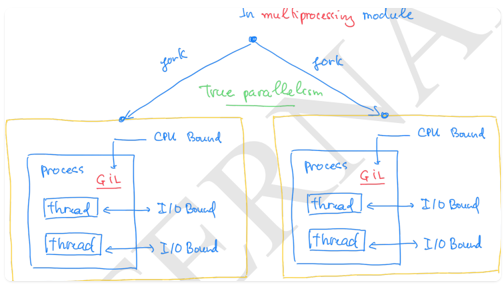

### Fork in Unix

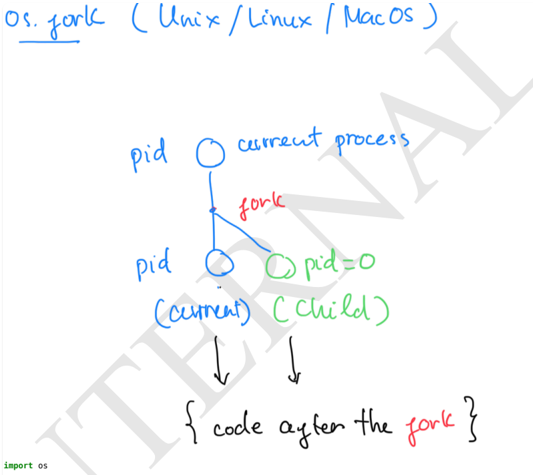

In multiprocessing, `fork`is a system call that exists on Unix-like operating systems. When a process calls `fork()`, the operating system creates a new process that is an almost exact copy of the parent process. The different is:
- Child process take output of 0 when `fork()` call
- Parant process return PID of the child

```python
import os

pid = os.fork()

if pid == 0:
    print("I am the CHILD process!")
else:
    print(f"I am the PARENT, child PID: {pid}")

**NOTE**: `os.fork()` is dangerous in multi-threaded programs because it copies threads and resources, which can cause deadlocks. Use the `multiprocessing` module instead.